In [1]:
print("Performed By Girish Sakpal(UIN: 231A011)")
import pandas as pd
from datasets import load_dataset
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt
from collections import Counter
from nltk import ngrams
import string
from wordcloud import WordCloud
import re

# Load complete IMDB dataset
dataset = load_dataset("stanfordnlp/imdb")

Performed By Girish Sakpal(UIN: 231A011)


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

...

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [2]:
print("Performed By Girish Sakpal(UIN: 231A011)")
#Combine and train an test
df = pd.concat(
    [dataset["train"].to_pandas(),
     dataset["test"].to_pandas()],
    ignore_index=True
)
#Rename Target Column
df = df.rename(columns={"label": "labels"})

print(df.shape)
print(df.columns)
print(df["labels"].value_counts())

Performed By Girish Sakpal(UIN: 231A011)
(50000, 2)
Index(['text', 'labels'], dtype='object')
labels
0    25000
1    25000
Name: count, dtype: int64


In [3]:
print("Performed By Girish Sakpal(UIN: 231A011)")
df.head()

Performed By Girish Sakpal(UIN: 231A011)


,text,labels
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [4]:
print("Performed By Girish Sakpal(UIN: 231A011)")
#Check duplicate and missing values
print("Missing Values:")
print(df.isna().sum())
print("\nNumber of Duplicate Values:")
print(df.duplicated().sum())

Performed By Girish Sakpal(UIN: 231A011)
Missing Values:
text      0
labels    0
dtype: int64

Number of Duplicate Values:
418


In [5]:
print("Performed By Girish Sakpal(UIN: 231A011)")
#basic text statistics
df["char_count"] = df["text"].astype(str).apply(len)
df["word_count"] = df["text"].astype(str).apply(lambda x: len(x.split()))
df["unique_word_count"] = df["text"].astype(str).apply(
    lambda x: len(set(x.lower().split()))
)
df["avg_word_length"] = df["text"].astype(str).apply(
    lambda x: sum(len(word) for word in x.split()) /
    max(len(x.split()), 1)
)
print("Test Statistics:")
print(
    df[
        ["char_count",
         "word_count",
         "unique_word_count",
         "avg_word_length"]
    ].describe()
)

Performed By Girish Sakpal(UIN: 231A011)
Test Statistics:
         char_count    word_count  unique_word_count  avg_word_length
count  50000.000000  50000.000000       50000.000000     50000.000000
mean    1309.431020    231.156940         148.049780         4.640676
std      989.728014    171.343997          88.837364         0.340731
min       32.000000      4.000000           4.000000         1.239865
25%      699.000000    126.000000          91.000000         4.417904
50%      970.000000    173.000000         120.000000         4.627006
75%     1590.250000    280.000000         180.000000         4.847458
max    13704.000000   2470.000000        1092.000000        12.290909


In [6]:
print("Performed By Girish Sakpal(UIN: 231A011)")
def clean_text(text):
    #Convert to lowercase
    text = text.lower()
    #Remove HTML tags
    text = re.sub(r"<.*?>", "", text)
    #Keep alphabetic characters only
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    #Remove extra whitespaces
    text = re.sub(r"\s+", " ", text).strip()
    return text

#Using 'text' instead of the non-existent 'review' column
df["clean_text"] = df["text"].astype(str).apply(clean_text)
print("\nOriginal Review:")
print(df["text"].iloc[10][:500])
print("\nCleaned Review:")
print(df["clean_text"].iloc[10][:500])

Performed By Girish Sakpal(UIN: 231A011)

Original Review:
It was great to see some of my favorite stars of 30 years ago including John Ritter, Ben Gazarra and Audrey Hepburn. They looked quite wonderful. But that was it. They were not given any characters or good lines to work with. I neither understood or cared what the characters were doing.<br /><br />Some of the smaller female roles were fine, Patty Henson and Colleen Camp were quite competent and confident in their small sidekick parts. They showed some talent and it is sad they didn't go on to st

Cleaned Review:
it was great to see some of my favorite stars of years ago including john ritter ben gazarra and audrey hepburn they looked quite wonderful but that was it they were not given any characters or good lines to work with i neither understood or cared what the characters were doingsome of the smaller female roles were fine patty henson and colleen camp were quite competent and confident in their small sidekick parts they sh

Performed By Girish Sakpal(UIN: 231A011)


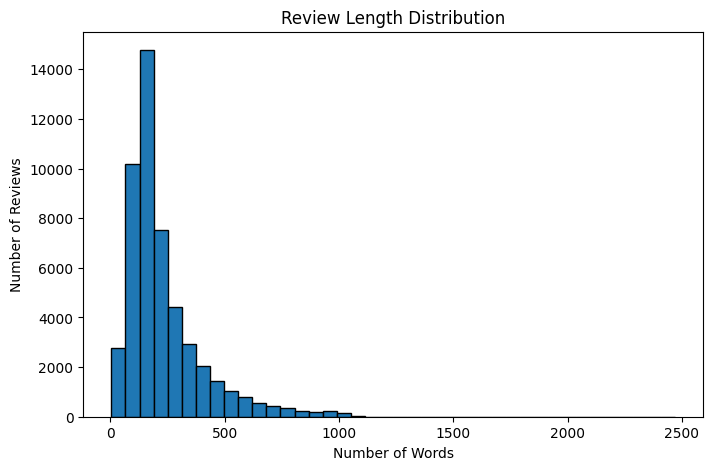

In [7]:
print("Performed By Girish Sakpal(UIN: 231A011)")
#Document Length Distribution
plt.figure(figsize=(8,5))
plt.hist(df["word_count"], bins=40, edgecolor="black")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.title("Review Length Distribution")
plt.show()

In [8]:
print("Performed By Girish Sakpal(UIN: 231A011)")
#Create word plot
all_words = " ".join(df["clean_text"]).split()
print("Total number of words:", len(all_words))
print("Vocabulary Size:", len(set(all_words)))

Performed By Girish Sakpal(UIN: 231A011)
Total number of words: 11259489
Vocabulary Size: 214620


Performed By Girish Sakpal(UIN: 231A011)


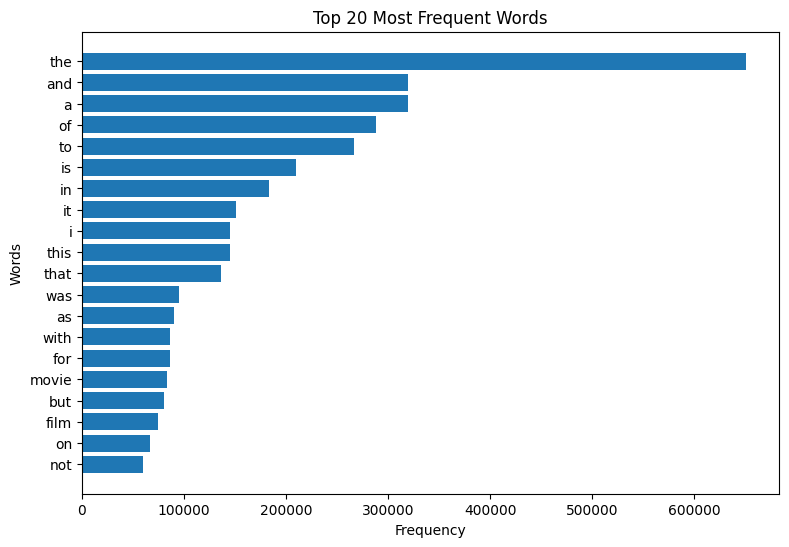

In [9]:
print("Performed By Girish Sakpal(UIN: 231A011)")
#Most Frequent Words
word_freq = Counter(all_words)
top_words = word_freq.most_common(20)
words = [word for word, count in top_words]
counts = [count for word, count in top_words]
plt.figure(figsize=(9,6))
plt.barh(words[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.title("Top 20 Most Frequent Words")
plt.show()

Performed By Girish Sakpal(UIN: 231A011)


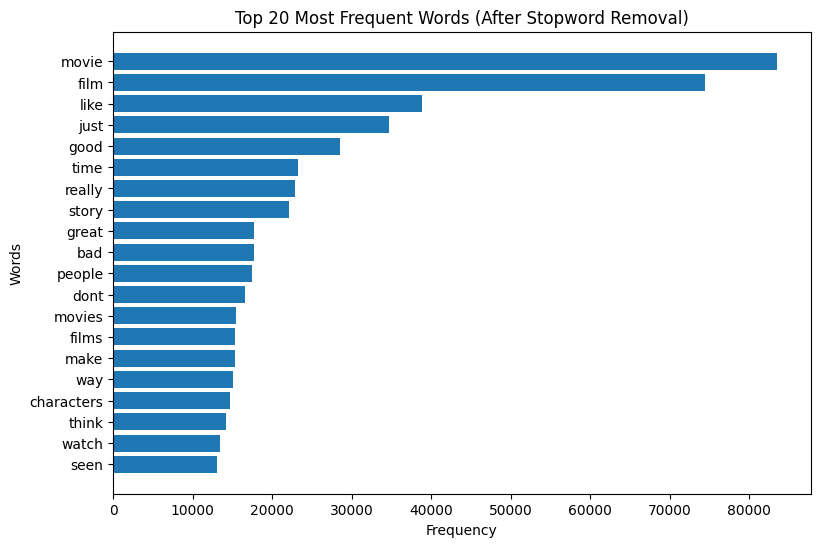

In [10]:
print("Performed By Girish Sakpal(UIN: 231A011)")
#Remove stopwords
vectorizer = CountVectorizer(
    stop_words="english",
)
vectorizer.fit(df["clean_text"])
stop_words = vectorizer.get_stop_words()
filtered_words = [word for word in all_words if word not in stop_words]
filtered_freq = Counter(filtered_words)
top_filtered = filtered_freq.most_common(20)
words = [word for word, count in top_filtered]
counts = [count for word, count in top_filtered]
plt.figure(figsize=(9,6))
plt.barh(words[::-1], counts[::-1])
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.title("Top 20 Most Frequent Words (After Stopword Removal)")
plt.show()

Performed By Girish Sakpal(UIN: 231A011)


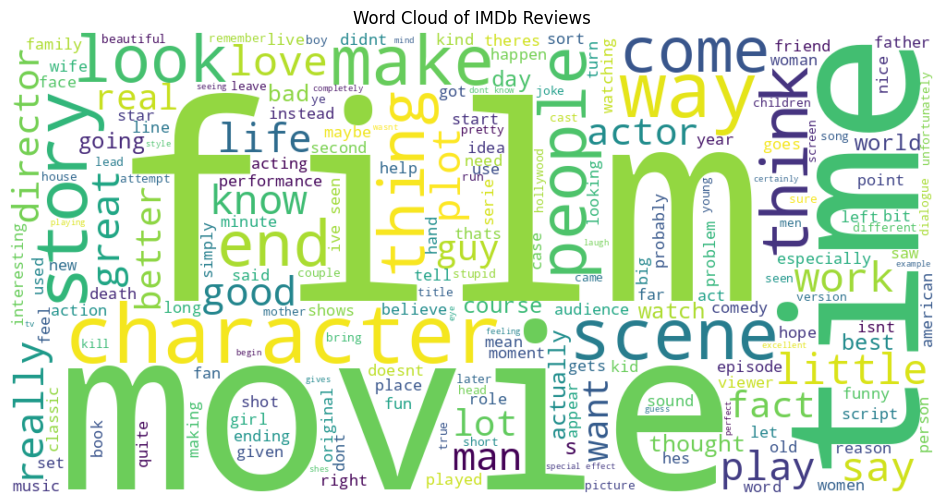

In [11]:
print("Performed By Girish Sakpal(UIN: 231A011)")
clean_text_combined = " ".join(filtered_words)
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
).generate(clean_text_combined)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of IMDb Reviews")
plt.show()

In [12]:
print("Performed By Girish Sakpal(UIN: 231A011)")
#Top Bigrams
bigram_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    max_features=20,
)
bigram_matrix = bigram_vectorizer.fit_transform(
    df["clean_text"])
bigram_counts = bigram_matrix.sum(axis=0).A1
bigram_names = bigram_vectorizer.get_feature_names_out()
bigram_df = pd.DataFrame(
    {"Bigram": bigram_names,
     "Frequency": bigram_counts}
)
bigram_df = bigram_df.sort_values(
    "Frequency", ascending=False
)

print("\nTop 20 Bigrams:")
print(bigram_df.head(20))

Performed By Girish Sakpal(UIN: 231A011)

Top 20 Bigrams:
             Bigram  Frequency
6          ive seen       3300
1         dont know       2193
15  special effects       2134
8        looks like       1661
11       movie just       1477
16       waste time       1425
5           im sure       1369
3        good movie       1363
17      watch movie       1296
2        dont think       1296
7         look like       1291
13         new york       1245
9        low budget       1224
19        years ago       1197
14      pretty good       1073
18         year old       1061
4       high school       1059
10   main character       1041
12       movie like       1038
0         bad movie        979
